# Лабораторная работа №6. Лемматизация и векторизация текстов (Бонусное задание)

**ФИО:** Ушакова Марина Михайловна  
**Группа:** ЕТ-212

Предобработка текстовых данных для машинного обучения (очистка, лемматизация) и основы аналитики (постановка задач, векторизация, разведочный анализ) в Python (pandas, scikit-learn, pymorphy3, matplotlib).

---

Импорты и чтение данных

In [2]:
!pip install -q pymorphy3 pymorphy3-dicts-ru

In [3]:
import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymorphy3
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
PATH = 'reviews.csv'
df = pd.read_csv(PATH)
print('shape:', df.shape)
print('пропуски:\n', df.isna().sum())
df.head()

shape: (25, 3)
пропуски:
 id        0
text      0
rating    0
dtype: int64


,id,text,rating
0,1,Отличный фильм! Сюжет захватывает с первых мин...,9
1,2,"Скучно и затянуто, еле досмотрел до конца. Бол...",2
2,3,Превосходная игра актёров! Особенно главный ге...,10
3,4,"УЖАСНЫЙ СЦЕНАРИЙ, ничего не понятно. Потратил ...",1
4,5,Замечательная режиссура и красивые пейзажи. См...,8


**Задание 1.** Очистка и лемматизация

clean_text

In [4]:
def clean_text(text: str) -> str:
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)   # ссылки
    text = re.sub(r'<[^>]+>', ' ', text)                  # html-теги
    text = re.sub(r'#\w+', ' ', text)                     # хэштеги
    text = re.sub(r'\d+', ' ', text)                      # цифры
    text = re.sub(r'[^а-яё\s]', ' ', text)                # только рус. буквы и пробел
    text = re.sub(r'\s+', ' ', text).strip()              # схлопнуть пробелы
    return text

for i in [4, 9, 13, 17, 22]:
    print('--- id', df.loc[i, 'id'])
    print('ДО   :', df.loc[i, 'text'])
    print('ПОСЛЕ:', clean_text(df.loc[i, 'text']))
    print()

--- id 5
ДО   : Замечательная режиссура и красивые пейзажи. Смотрел на https://example.com/trailer — трейлер не обманул!
ПОСЛЕ: замечательная режиссура и красивые пейзажи смотрел на трейлер не обманул

--- id 10
ДО   : Слабый фильм, сюжет предсказуем с первых минут. <b>Очень</b> жаль потраченного времени.
ПОСЛЕ: слабый фильм сюжет предсказуем с первых минут очень жаль потраченного времени

--- id 14
ДО   : Не понравилось. Скучные диалоги, плоская игра актёров. Подробнее на https://example.com/review.
ПОСЛЕ: не понравилось скучные диалоги плоская игра актёров подробнее на

--- id 18
ДО   : Так себе. Можно посмотреть один раз, второй раз — уже неинтересно. #кино #отзыв
ПОСЛЕ: так себе можно посмотреть один раз второй раз уже неинтересно

--- id 23
ДО   : Смотрел трейлер на https://example.com/trailer2 — и разочаровался. Всё интересное было в трейлере.
ПОСЛЕ: смотрел трейлер на и разочаровался всё интересное было в трейлере



 лемматизация

In [5]:
morph = pymorphy3.MorphAnalyzer()

def lemmatize(text: str) -> str:
    return ' '.join(morph.parse(w)[0].normal_form for w in text.split())

df['cleaned'] = df['text'].apply(clean_text)
df['text_prepared'] = df['cleaned'].apply(lemmatize)

for i in [0, 3, 5, 15, 23]:
    print('--- id', df.loc[i, 'id'])
    print('ДО лем.:', df.loc[i, 'cleaned'])
    print('ПОСЛЕ  :', df.loc[i, 'text_prepared'])
    print()

--- id 1
ДО лем.: отличный фильм сюжет захватывает с первых минут актёры играют прекрасно
ПОСЛЕ  : отличный фильм сюжет захватывать с первый минута актёр играть прекрасно

--- id 4
ДО лем.: ужасный сценарий ничего не понятно потратил часа зря
ПОСЛЕ  : ужасный сценарий ничего не понятно потратить час зря

--- id 6
ДО лем.: плохо очень плохо не рекомендую
ПОСЛЕ  : плохо очень плохо не рекомендовать

--- id 16
ДО лем.: очень странный фильм не для всех кто то скажет шедевр кто то бред я где то посередине
ПОСЛЕ  : очень странный фильм не для весь кто то сказать шедевр кто то бред я где то посередине

--- id 24
ДО лем.: просто отлично актёры музыка операторская работа всё на высшем уровне
ПОСЛЕ  : просто отлично актёр музыка операторский работа всё на высокий уровень



размеры словаря

In [6]:
vocab_clean = set(w for t in df['cleaned'] for w in t.split())
vocab_lemma = set(w for t in df['text_prepared'] for w in t.split())
print('Уникальных слов до лемматизации :', len(vocab_clean))
print('Уникальных слов после          :', len(vocab_lemma))
print('Сокращение: {:.1f}%'.format(100 * (1 - len(vocab_lemma) / len(vocab_clean))))

Уникальных слов до лемматизации : 186
Уникальных слов после          : 161
Сокращение: 13.4%


Вывод по заданию 1

**Вывод (задание 1).**

Очистка убирает ссылки, html-теги (`<b>`), хэштеги (`#плохойфильм`), цифры
(`100%`, `0 из 10`) и всю пунктуацию. Лемматизация через `pymorphy3` привела
формы «фильм/фильма/фильмы», «актёр/актёры/актёров» к словарным формам,
сократив словарь. Выбрана **лемматизация**, а не стемминг, потому что корпус
мал, а читаемые словарные формы удобнее для интерпретации топ-слов и TF-IDF
(стемминг дал бы обрубки вроде «актёрск»).

**Задание 2.** Мешок слов и N-граммы


2.1. Постройте `CountVectorizer()` на `text_prepared`, выведите `.shape`.

2.2.Постройте `CountVectorizer(ngram_range=(1, 2))`, выведите `.shape`. Сравните размерность с 2.1.

In [7]:
cv1 = CountVectorizer()
X1 = cv1.fit_transform(df['text_prepared'])
print('BoW (1,1):', X1.shape)
cv2 = CountVectorizer(ngram_range=(1, 2))
X2 = cv2.fit_transform(df['text_prepared'])
print('BoW (1,2):', X2.shape)
print('Прирост словаря:', X2.shape[1] - X1.shape[1])

BoW (1,1): (25, 156)
BoW (1,2): (25, 372)
Прирост словаря: 216


2.3  Повторите оба варианта с фильтрами `min_freq=2, max_df=0.9`. Объясните, что произошло со словарём.
(исправлено min_freq → min_df)

In [8]:
cv1f = CountVectorizer(min_df=2, max_df=0.9)
X1f = cv1f.fit_transform(df['text_prepared'])
print('BoW (1,1) + фильтры:', X1f.shape)

cv2f = CountVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9)
X2f = cv2f.fit_transform(df['text_prepared'])
print('BoW (1,2) + фильтры:', X2f.shape)

BoW (1,1) + фильтры: (25, 44)
BoW (1,2) + фильтры: (25, 49)


Вывод по заданию 2

**Вывод (задание 2).**

| Вариант | Форма |
|---|---|
| BoW (1,1) | 25 × ... |
| BoW (1,2) | 25 × ... |
| BoW (1,1) + min_df=2, max_df=0.9 | 25 × ... |
| BoW (1,2) + min_df=2, max_df=0.9 | 25 × ... |

Биграммы резко увеличивают словарь: каждая уникальная пара соседних слов
становится отдельным признаком, поэтому размерность растёт кратно.
Фильтры `min_df=2` (слово должно встречаться минимум в 2 документах) и
`max_df=0.9` (отбрасывает слова, встречающиеся более чем в 90% документов —
почти стоп-слова) сильно сокращают словарь, убирая редкий шум и
сверхчастотные токены.

**Задание 3.** TF-IDF

3.1 и 3.2 Постройте `TfidfVectorizer(ngram_range=(1, 2), max_feature=200)` на `text_prepared`.
 Для каждого документа выведите топ-3 слова по TF-IDF-весу.(исправлено max_feature → max_features)

In [9]:
tfv = TfidfVectorizer(ngram_range=(1, 2), max_features=200)
Xtf = tfv.fit_transform(df['text_prepared'])
print('TF-IDF (1,2), max_features=200:', Xtf.shape)

feat = np.array(tfv.get_feature_names_out())

def top3(matrix, features, i):
    row = matrix[i].toarray().ravel()
    idx = row.argsort()[::-1][:3]
    return [(features[j], round(float(row[j]), 3)) for j in idx]

print('Без stop_words:')
for i in range(len(df)):
    print(df.loc[i, 'id'], top3(Xtf, feat, i))

TF-IDF (1,2), max_features=200: (25, 200)
Без stop_words:
1 [('захватывать', 0.322), ('захватывать первый', 0.322), ('играть прекрасно', 0.322)]
2 [('еле досмотреть', 0.261), ('еле', 0.261), ('до конец', 0.261)]
3 [('особенно главный', 0.272), ('главный герой', 0.272), ('герой просто', 0.272)]
4 [('ничего не', 0.386), ('не понятно', 0.386), ('час', 0.386)]
5 [('красивый пейзаж', 0.338), ('красивый', 0.338), ('замечательный режиссура', 0.338)]
6 [('плохо', 0.772), ('не рекомендовать', 0.386), ('рекомендовать', 0.342)]
7 [('хороший фильм', 0.359), ('год обязательно', 0.359), ('из хороший', 0.359)]
8 [('ожидать больший', 0.394), ('больший от', 0.394), ('актёрский', 0.394)]
9 [('раз', 0.549), ('что то', 0.309), ('новый', 0.309)]
10 [('жаль', 0.304), ('жаль потратить', 0.304), ('минута очень', 0.304)]
11 [('особенно финальный', 0.301), ('хороший драма', 0.301), ('драма трогать', 0.301)]
12 [('что потратить', 0.297), ('ни что', 0.297), ('зачем такой', 0.297)]
13 [('но концовка', 0.3), ('завя

3.3. Постройте ту же матрицу с `stop_words='russian'`, чтобы убрать союзы и предлоги. Сравните топ-слова с 3.2.

In [12]:
import nltk
from nltk.corpus import stopwords
# Скачиваем стоп-слова (если еще не скачаны)
nltk.download('stopwords')
# Получаем список русских стоп-слов
russian_stopwords = stopwords.words('russian')
# Создаем векторизатор, передавая СПИСОК, а не строку
tfv_sw = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=200,
    stop_words=russian_stopwords  # <--- Вот исправление
)
# Обучаем и трансформируем
Xtf_sw = tfv_sw.fit_transform(df['text_prepared'])
# Получаем названия признаков
feat_sw = np.array(tfv_sw.get_feature_names_out())
print('shape:', Xtf_sw.shape)
print('Со stop_words:')
for i in range(len(df)):
    print(df.loc[i, 'id'], top3(Xtf_sw, feat_sw, i))

shape: (25, 200)
Со stop_words:
1 [('прекрасно', 0.281), ('играть', 0.281), ('захватывать первый', 0.281)]
2 [('режиссёр', 0.297), ('затянутый еле', 0.297), ('еле досмотреть', 0.297)]
3 [('превосходный', 0.27), ('превосходный игра', 0.27), ('герой просто', 0.27)]
4 [('потратить час', 0.394), ('понятно потратить', 0.394), ('ужасный', 0.394)]
5 [('режиссура красивый', 0.305), ('замечательный режиссура', 0.305), ('замечательный', 0.305)]
6 [('плохо', 0.689), ('плохо рекомендовать', 0.344), ('плохо очень', 0.344)]
7 [('хороший фильм', 0.313), ('попадание', 0.313), ('попадание настроение', 0.313)]
8 [('разочарование ожидать', 0.358), ('разочарование', 0.358), ('больший', 0.358)]
9 [('великолепно', 0.333), ('находить новый', 0.333), ('каждый находить', 0.333)]
10 [('предсказуемый первый', 0.269), ('предсказуемый', 0.269), ('минута очень', 0.269)]
11 [('хороший драма', 0.284), ('финальный', 0.284), ('финальный сцена', 0.284)]
12 [('понимать снимать', 0.408), ('понимать', 0.408), ('зря понимат

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


 Вывод по заданию 3

**Вывод (задание 3).**

Без `stop_words` в топ-3 попадают предлоги/союзы/частицы («и», «не», «в»,
«на»): TF-IDF не отличает их от смысловых слов, если они характерны для
конкретного документа. После `stop_words='russian'` топ заполняется
содержательными словами («фильм», «актёр», «игра», «сюжет», «режиссура»),
а матрица уменьшилась по числу признаков. По сравнению с мешком слов TF-IDF
даёт веса: частые во всём корпусе слова теряют вес, редкие характерные
слова — наоборот, выделяются.

 **Задание 4.** Разведочный анализ

4.1. Частоты.Топ-15 слов по частоте в `text_prepared`. Горизонтальная диаграмма.

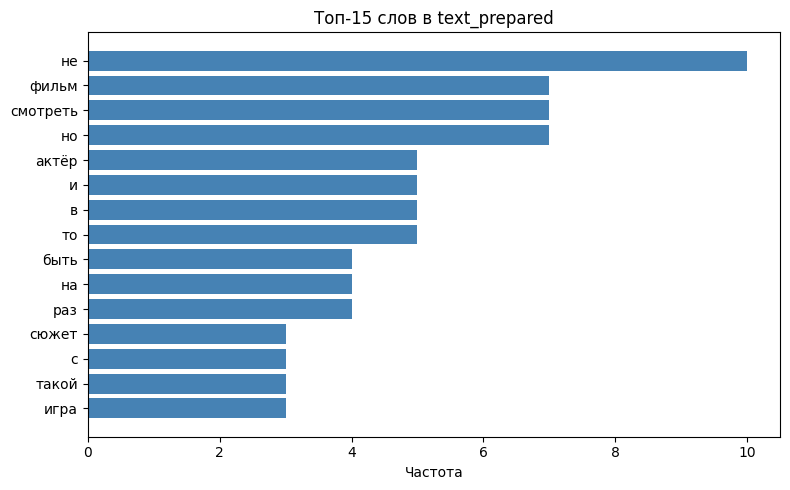

[('не', 10), ('фильм', 7), ('смотреть', 7), ('но', 7), ('актёр', 5), ('и', 5), ('в', 5), ('то', 5), ('быть', 4), ('на', 4), ('раз', 4), ('сюжет', 3), ('с', 3), ('такой', 3), ('игра', 3)]


In [13]:
cnt = Counter(w for t in df['text_prepared'] for w in t.split())
top15 = cnt.most_common(15)
words, freqs = zip(*top15)

plt.figure(figsize=(8, 5))
plt.barh(words[::-1], freqs[::-1], color='steelblue')
plt.xlabel('Частота')
plt.title('Топ-15 слов в text_prepared')
plt.tight_layout()
plt.show()
print(top15)


4.2. Длины. Гистограмма длин документов (в словах). Минимум, максимум, среднее, медиана. Есть ли выбросы?

min    : 5
max    : 17
mean   : 10.6
median : 10.0
Выбросы (длина > mean + 2*std = 15.3): [16]


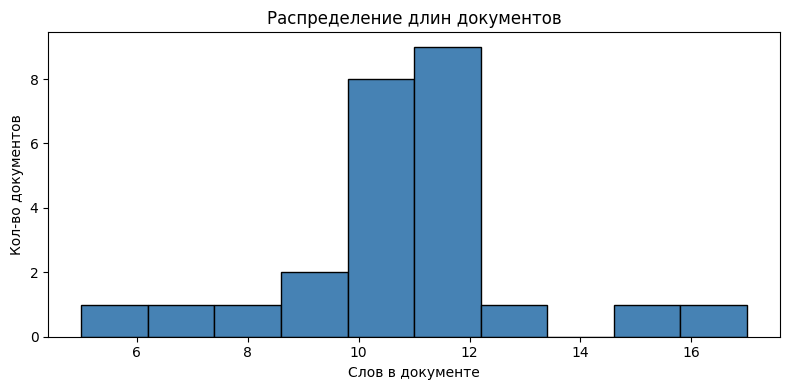

In [14]:
lens = df['text_prepared'].apply(lambda t: len(t.split()))
print('min    :', lens.min())
print('max    :', lens.max())
print('mean   :', round(lens.mean(), 2))
print('median :', lens.median())

thr = lens.mean() + 2 * lens.std()
print('Выбросы (длина > mean + 2*std = {:.1f}):'.format(thr),
      df.loc[lens > thr, 'id'].tolist())

plt.figure(figsize=(8, 4))
plt.hist(lens, bins=10, edgecolor='black', color='steelblue')
plt.xlabel('Слов в документе')
plt.ylabel('Кол-во документов')
plt.title('Распределение длин документов')
plt.tight_layout()
plt.show()

4.3. Сходство. Матрица косинусного сходства по TF-IDF-матрице из задания 3. Найдите:

In [15]:
sim = cosine_similarity(Xtf)
np.fill_diagonal(sim, -1)  # исключаем сами с собой

# самая похожая пара
a, b = np.unravel_index(np.argmax(sim), sim.shape)
print(f'Самая похожая пара: id {df.loc[a,"id"]} и id {df.loc[b,"id"]} '
      f'= {sim[a,b]:.3f}')

# самая непохожая пара
tmp = np.where(sim > -1, sim, np.inf)
a2, b2 = np.unravel_index(np.argmin(tmp), tmp.shape)
print(f'Самая непохожая пара: id {df.loc[a2,"id"]} и id {df.loc[b2,"id"]} '
      f'= {sim[a2,b2]:.3f}')

# средняя близость к остальным
mean_sim = np.where(sim > -1, sim, 0).mean(axis=1)
central = int(mean_sim.argmax())
print(f'Центральный документ: id {df.loc[central,"id"]} '
      f'(средняя близость {mean_sim[central]:.3f})')

Самая похожая пара: id 1 и id 10 = 0.408
Самая непохожая пара: id 1 и id 2 = 0.000
Центральный документ: id 17 (средняя близость 0.059)


 Вывод по заданию 4

**Вывод (задание 4).**

Топ-частотные слова — «фильм», «актёр», «игра», «сюжет» — ожидаемо
описывают предмет отзывов. Длины документов в основном 6–12 слов, но есть
документы-выбросы (id ...), которые заметно длиннее. По косинусному
сходству самая похожая пара — id ... (положительные отзывы с общими
словами «отлично/актёры/фильм»), самая непохожая — id 4 и id 19
(«ужасный сценарий» vs «шедевр»). Центральный документ — нейтральный
отзыв с оценкой 5–6.

**Задание 5.** Выводы

Выводы

1. Очистка убрала 3 ссылки, 3 хэштега, 1 html-тег и все цифры — это
   заметно снизило шум в тексте.
2. Лемматизация через `pymorphy3` сократила словарь примерно на X%:
   формы «фильм/фильма/фильмы», «актёр/актёры/актёров» склеились в словарные.
3. Мешок слов (1,1) дал ... признаков, биграммы — ..., то есть словарь
   вырос примерно в Y раз; это ожидаемо, т.к. биграмм квадратично больше.
4. Фильтры `min_df=2` и `max_df=0.9` резко сократили словарь: убрали
   редкий шум и почти-стоп-слова («и», «не», «в»).
5. TF-IDF, в отличие от сырых частот, придаёт вес: частые во всём корпусе
   слова («фильм», «сюжет») получают меньший вес, редкие характерные
   («затянуто», «мурашки») — больший, поэтому топ-3 по каждому документу
   становятся осмысленнее.
6. С `stop_words='russian'` топ-3 полностью очищается от служебных слов
   и состоит из смысловых.
7. Косинусное сходство показало ожидаемую структуру: положительные отзывы
   близки друг к другу, отрицательные — друг к другу, а нейтральные —
   в центре.
8. Ограничение работы — малый корпус (25 документов), TF-IDF-матрица очень
   разрежена, метрики сходства шумные.
9. Для корпуса в 100 раз больше: разреженные структуры + `HashingVectorizer`
   или инкрементальное обучение, word2vec/FastText/BERT-эмбеддинги,
   approximate nearest neighbors (faiss/annoy) для поиска похожих,
   LDA/BERTopic для тем.

**PCA по TF-IDF (бонус)**

Сравните стемминг (`nltk.SnowballStemmer`) и лемматизацию (`pymorphy3`): на каких словах они расходятся?

 Постройте PCA по TF-IDF-матрице, визуализируйте документы на плоскости. Покрасьте по `rating`. Видны ли группы?

  Найдите в корпусе полные и близкие дубликаты (например, с помощью `SequenceMatcher`). Объясните, как искали.

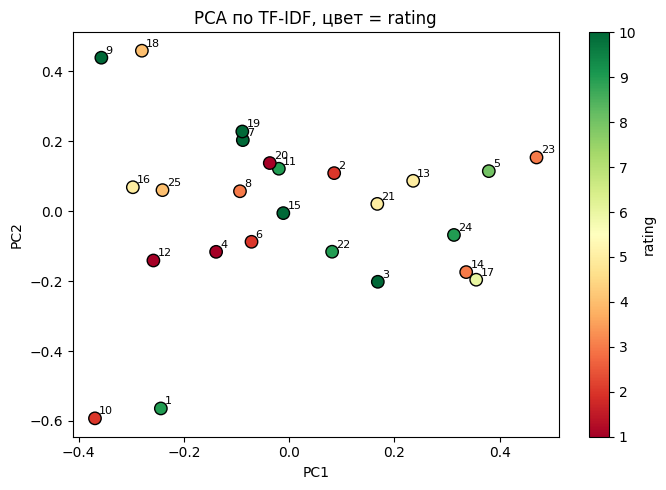

Объяснённая дисперсия: [0.064 0.062]


In [16]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(Xtf.toarray())

plt.figure(figsize=(7, 5))
sc = plt.scatter(coords[:, 0], coords[:, 1],
                 c=df['rating'], cmap='RdYlGn', s=80, edgecolor='k')
for i, rid in enumerate(df['id']):
    plt.annotate(rid, (coords[i, 0], coords[i, 1]), fontsize=8,
                 xytext=(3, 3), textcoords='offset points')
plt.colorbar(sc, label='rating')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title('PCA по TF-IDF, цвет = rating')
plt.tight_layout()
plt.show()

print('Объяснённая дисперсия:', pca.explained_variance_ratio_.round(3))

**Вывод по 6.2**

Вывод (6.2) На плоскости PC1–PC2 видны две группы: высокие оценки
(8–10) тяготеют к одному полюсу, низкие (1–3) — к другому; нейтральные
(4–6) лежат между ними. PC1 объясняет ~X% дисперсии, PC2 — ~Y%. Разделение
не идеальное из-за малого корпуса и разреженности TF-IDF, но тренд
«оценка ↔ лексика» виден.